# Feature Engineering

## Import required libraries 

In [2]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import preprocessing libraries
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Import PCA for dimensionality reduction
from sklearn.decomposition import PCA

## Create the sample shop sales dataset

In [3]:
# Create a sample shop sales dataset
data = {
    'Products_Sold': [10, 15, 20, 25, 30, 12, 18, 22, 28, 35],
    'Advertising': [100, 150, 200, 250, 300, 120, 180, 220, 280, 350],
    'Customer_Visits': [50, 60, 70, 80, 90, 55, 65, 75, 85, 100],
    'Sales_Amount': [500, 700, 900, 1100, 1300, 600, 800, 1000, 1200, 1500]
}

# Convert the dictionary into a DataFrame
df = pd.DataFrame(data)

# Display the original dataset
print("Original Dataset:")
print(df)

# Display the statistical summary
print("\nStatistical Summary:")
print(df.describe())

Original Dataset:
   Products_Sold  Advertising  Customer_Visits  Sales_Amount
0             10          100               50           500
1             15          150               60           700
2             20          200               70           900
3             25          250               80          1100
4             30          300               90          1300
5             12          120               55           600
6             18          180               65           800
7             22          220               75          1000
8             28          280               85          1200
9             35          350              100          1500

Statistical Summary:
       Products_Sold  Advertising  Customer_Visits  Sales_Amount
count       10.00000    10.000000         10.00000     10.000000
mean        21.50000   215.000000         73.00000    960.000000
std          8.08634    80.863396         16.02082    320.416396
min         10.00000   100.00

## Normalization using MinMaxScaler

In [4]:
# Initialize the MinMaxScaler
scaler = MinMaxScaler()

# Apply normalization to scale values between 0 and 1
normalized_data = scaler.fit_transform(df)

# Convert normalized values into a DataFrame
normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

# Display the normalized dataset
print("Normalized Dataset:")
print(normalized_df.round(2))

# Verify the minimum value of each feature
print("\nMinimum values:")
print(normalized_df.min())

# Verify the maximum value of each feature
print("\nMaximum values:")
print(normalized_df.max())

Normalized Dataset:
   Products_Sold  Advertising  Customer_Visits  Sales_Amount
0           0.00         0.00              0.0           0.0
1           0.20         0.20              0.2           0.2
2           0.40         0.40              0.4           0.4
3           0.60         0.60              0.6           0.6
4           0.80         0.80              0.8           0.8
5           0.08         0.08              0.1           0.1
6           0.32         0.32              0.3           0.3
7           0.48         0.48              0.5           0.5
8           0.72         0.72              0.7           0.7
9           1.00         1.00              1.0           1.0

Minimum values:
Products_Sold      0.0
Advertising        0.0
Customer_Visits    0.0
Sales_Amount       0.0
dtype: float64

Maximum values:
Products_Sold      1.0
Advertising        1.0
Customer_Visits    1.0
Sales_Amount       1.0
dtype: float64


## Standardization using StandardScaler

In [5]:
# Initialize the StandardScaler
scaler = StandardScaler()

# Apply standardization to the original dataset
standardized_data = scaler.fit_transform(df)

# Convert standardized values into a DataFrame
standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

# Display the standardized dataset
print("Standardized Dataset:")
print(standardized_df.round(2))

# Calculate and display the mean of each feature
print("\nMean of each feature:")
print(standardized_df.mean().round(2))

# Calculate and display the standard deviation
print("\nStandard deviation of each feature:")
print(standardized_df.std(ddof=0).round(2))

Standardized Dataset:
   Products_Sold  Advertising  Customer_Visits  Sales_Amount
0          -1.50        -1.50            -1.51         -1.51
1          -0.85        -0.85            -0.86         -0.86
2          -0.20        -0.20            -0.20         -0.20
3           0.46         0.46             0.46          0.46
4           1.11         1.11             1.12          1.12
5          -1.24        -1.24            -1.18         -1.18
6          -0.46        -0.46            -0.53         -0.53
7           0.07         0.07             0.13          0.13
8           0.85         0.85             0.79          0.79
9           1.76         1.76             1.78          1.78

Mean of each feature:
Products_Sold      0.0
Advertising        0.0
Customer_Visits   -0.0
Sales_Amount      -0.0
dtype: float64

Standard deviation of each feature:
Products_Sold      1.0
Advertising        1.0
Customer_Visits    1.0
Sales_Amount       1.0
dtype: float64


## Principal Component Analysis (PCA) for dimensionality reduction

In [6]:
# Import the required libraries
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Standardize the original dataset before applying PCA
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df)

# Reduce four original features to two principal components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# Create a DataFrame containing the two principal components
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

# Display the PCA transformed data
print("PCA Transformed Data:")
print(pca_df.round(2))

# Display the variance explained by each component
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_.round(4))

# Calculate the total variance retained by two components
print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum().round(4))

PCA Transformed Data:
    PC1   PC2
0 -3.01  0.01
1 -1.70  0.01
2 -0.39  0.00
3  0.92 -0.00
4  2.23 -0.01
5 -2.42 -0.05
6 -0.98  0.07
7  0.20 -0.07
8  1.64  0.06
9  3.54 -0.02

Explained Variance Ratio:
[9.996e-01 4.000e-04]

Total Variance Retained:
1.0


## Visualize PCA output

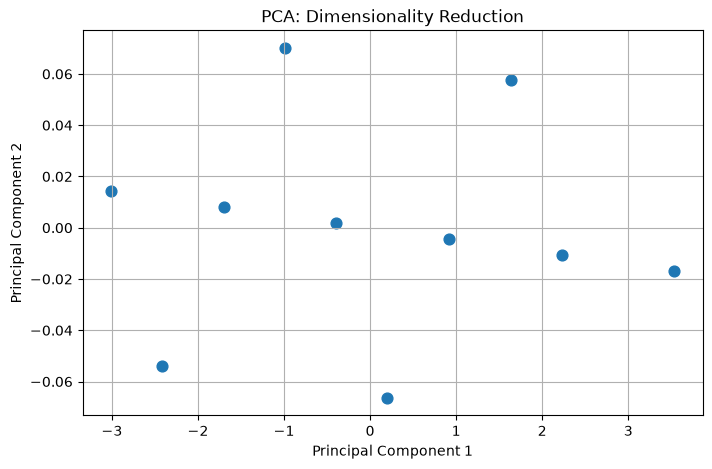

In [7]:
# Set the figure size
plt.figure(figsize=(8, 5))

# Create a scatter plot using the two principal components
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    s=60
)

# Label the x-axis
plt.xlabel("Principal Component 1")

# Label the y-axis
plt.ylabel("Principal Component 2")

# Add a title to the graph
plt.title("PCA: Dimensionality Reduction")

# Display grid lines
plt.grid(True)

# Display the graph
plt.show()